# Classificazione del piede preferito dei giocatori FC25

## Previsione di giocatori destri e mancini

L'obiettivo è verificare se le statistiche tecniche permettono di distinguere i giocatori mancini dai destri. Il problema è binario, ma le due classi non hanno la stessa numerosità: circa tre giocatori su quattro sono destri.

Questa caratteristica rende insufficiente una valutazione basata soltanto sull'accuracy. Un modello che assegna sempre la classe `Destro` raggiunge infatti un valore apparentemente elevato senza riconoscere alcun mancino.

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ['LOKY_MAX_CPU_COUNT'] = '1'

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

DATA_PATH = Path('../data/puliti/movimento_puliti.csv')
FIG_DIR = Path('figure_classificazione')
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f'Giocatori caricati: {len(df):,}')

Giocatori caricati: 15,738


## 1. Variabile da prevedere e distribuzione delle classi

La classe positiva è rappresentata dai mancini:

- `0`: destro;
- `1`: mancino.

La colonna testuale `Preferred foot` viene utilizzata soltanto per costruire la variabile da prevedere e non viene inserita tra le caratteristiche del modello.

,Giocatori,Percentuale
Destro,11823,75.1%
Mancino,3915,24.9%


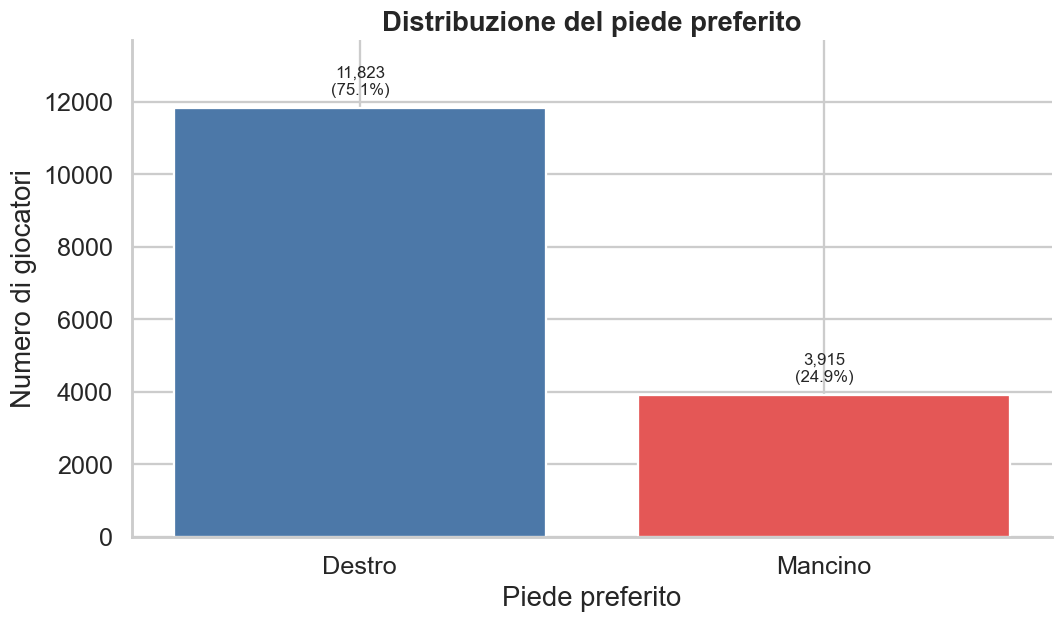

In [2]:
df_classification = df.copy()
df_classification['is_left_footed'] = (
    df_classification['Preferred foot'].eq('Left').astype(int)
)

FOOT_LABELS = ['Destro', 'Mancino']
target_counts = (
    df_classification['is_left_footed']
    .value_counts()
    .reindex([0, 1])
)
target_percentages = target_counts / target_counts.sum() * 100

distribution_table = pd.DataFrame({
    'Giocatori': target_counts.values,
    'Percentuale': target_percentages.values,
}, index=FOOT_LABELS)
display(distribution_table.style.format({'Percentuale': '{:.1f}%'}))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    FOOT_LABELS,
    target_counts.values,
    color=['#4c78a8', '#e45756'],
)
ax.set_title('Distribuzione del piede preferito')
ax.set_xlabel('Piede preferito')
ax.set_ylabel('Numero di giocatori')
ax.set_ylim(0, target_counts.max() * 1.16)

for bar, count, percentage in zip(
    bars, target_counts.values, target_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + target_counts.max() * 0.025,
        f'{count:,}\n({percentage:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
    )

fig.tight_layout()
fig.savefig(FIG_DIR / '07_distribuzione_piede.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Caratteristiche utilizzate

Per rendere il risultato confrontabile con quello del macroruolo vengono mantenute le stesse 29 statistiche tecniche dettagliate. Sono escluse tutte le informazioni testuali, le posizioni, l'OVR e le statistiche aggregate.

In questo modo il modello deve cercare eventuali associazioni tra piede preferito e profilo tecnico, senza ricevere direttamente informazioni costruite a partire dalla risposta.

In [3]:
technical_features = [
    'Acceleration', 'Sprint Speed',
    'Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
    'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing', 'Long Passing', 'Curve',
    'Dribbling', 'Agility', 'Balance', 'Reactions', 'Ball Control', 'Composure',
    'Interceptions', 'Heading Accuracy', 'Def Awareness', 'Standing Tackle', 'Sliding Tackle',
    'Jumping', 'Stamina', 'Strength', 'Aggression',
]

missing_columns = [
    column for column in technical_features
    if column not in df_classification.columns
]
if missing_columns:
    raise ValueError(f'Colonne mancanti: {missing_columns}')

X = df_classification[technical_features].copy()
y = df_classification['is_left_footed'].copy()

print(f'Caratteristiche utilizzate: {X.shape[1]}')
print(f'Valori mancanti: {int(X.isna().sum().sum())}')

Caratteristiche utilizzate: 29
Valori mancanti: 0


## 3. Suddivisione dei dati e riferimento

Il dataset viene diviso in training set (70%) e test set (30%) mantenendo la proporzione fra destri e mancini.

Il riferimento assegna a tutti i giocatori la classe più frequente, cioè `Destro`. La sua accuracy rappresenta il valore minimo che un modello utile dovrebbe superare, ma il confronto deve considerare anche quanti mancini vengono effettivamente riconosciuti.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

baseline_class = int(y_train.value_counts().idxmax())
baseline_train_pred = np.full(len(y_train), baseline_class)
baseline_test_pred = np.full(len(y_test), baseline_class)

print(f'Giocatori nel training set: {len(X_train):,}')
print(f'Giocatori nel test set: {len(X_test):,}')
print(f'Accuracy del riferimento: {accuracy_score(y_test, baseline_test_pred):.2%}')
print(f'Recall dei mancini nel riferimento: {recall_score(y_test, baseline_test_pred):.2%}')

Giocatori nel training set: 11,016
Giocatori nel test set: 4,722
Accuracy del riferimento: 75.12%
Recall dei mancini nel riferimento: 0.00%


## 4. Modelli confrontati

Vengono esaminate tre soluzioni:

1. regressione logistica standard;
2. regressione logistica con pesi inversamente proporzionali alla numerosità delle classi;
3. SVM con kernel RBF e lo stesso bilanciamento.

Il bilanciamento non crea nuovi giocatori e non modifica il test set: assegna semplicemente un peso maggiore agli errori commessi sulla classe meno numerosa durante l'addestramento.

La standardizzazione viene stimata esclusivamente sul training set ed è necessaria soprattutto per rendere confrontabili le distanze utilizzate dalla SVM.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_standard = LogisticRegression(
    max_iter=2000,
    random_state=42,
)
logistic_standard.fit(X_train_scaled, y_train)

logistic_balanced = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight='balanced',
)
logistic_balanced.fit(X_train_scaled, y_train)

svm_balanced = SVC(
    kernel='rbf',
    class_weight='balanced',
)
svm_balanced.fit(X_train_scaled, y_train)

predictions = {
    'Riferimento': {
        'train': baseline_train_pred,
        'test': baseline_test_pred,
    },
    'Logistica standard': {
        'train': logistic_standard.predict(X_train_scaled),
        'test': logistic_standard.predict(X_test_scaled),
    },
    'Logistica bilanciata': {
        'train': logistic_balanced.predict(X_train_scaled),
        'test': logistic_balanced.predict(X_test_scaled),
    },
    'SVM bilanciata': {
        'train': svm_balanced.predict(X_train_scaled),
        'test': svm_balanced.predict(X_test_scaled),
    },
}

print('Addestramento completato.')

Addestramento completato.


## 5. Valutazione

La classe di maggiore interesse è quella dei mancini. Vengono quindi riportate:

- **precision dei mancini**: fra i giocatori previsti come mancini, quanti lo sono realmente;
- **recall dei mancini**: quanti mancini reali vengono riconosciuti;
- **F1-score dei mancini**: equilibrio fra precision e recall;
- **F1-score macro**: media dell'F1-score di destri e mancini, attribuendo lo stesso peso alle due classi.

,Accuracy training,Accuracy test,Precision mancini,Recall mancini,F1 mancini,F1 macro
Modello,,,,,,
Riferimento,0.7513,0.7512,0.0000,0.0000,0.0000,0.4290
Logistica standard,0.7595,0.7558,0.5833,0.0655,0.1178,0.4881
Logistica bilanciata,0.6221,0.6355,0.3702,0.6630,0.4751,0.5980
SVM bilanciata,0.6963,0.6631,0.3892,0.6221,0.4789,0.6150


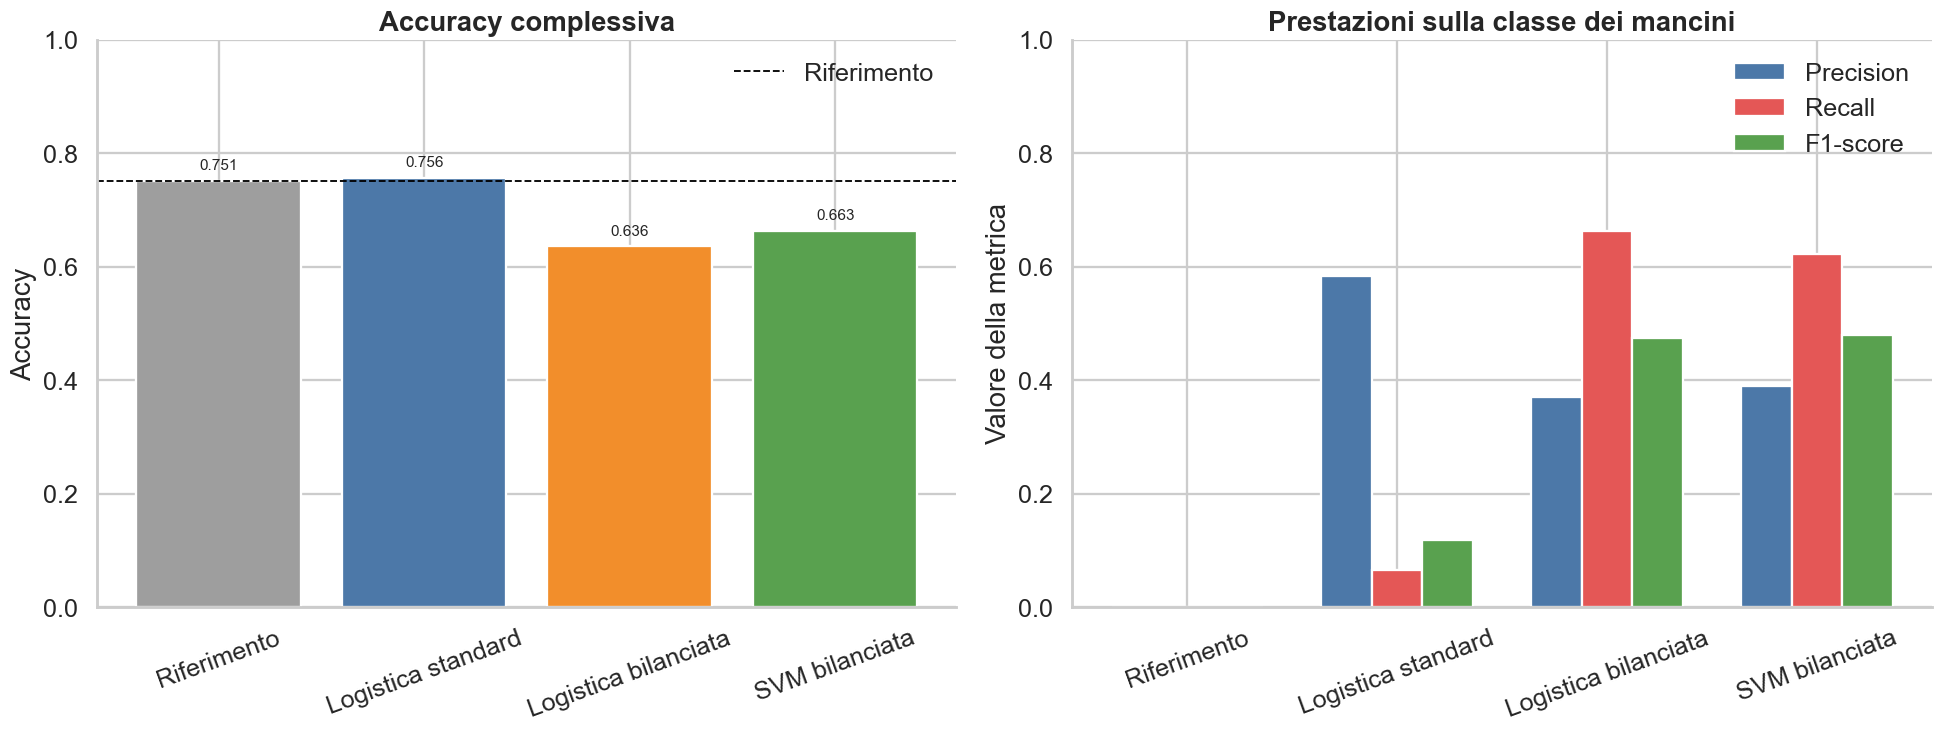

In [6]:
metric_rows = []

for model_name, model_predictions in predictions.items():
    y_pred_train = model_predictions['train']
    y_pred_test = model_predictions['test']
    metric_rows.append({
        'Modello': model_name,
        'Accuracy training': accuracy_score(y_train, y_pred_train),
        'Accuracy test': accuracy_score(y_test, y_pred_test),
        'Precision mancini': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall mancini': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 mancini': f1_score(y_test, y_pred_test, zero_division=0),
        'F1 macro': f1_score(
            y_test, y_pred_test, average='macro', zero_division=0
        ),
    })

metrics_table = pd.DataFrame(metric_rows).set_index('Modello')
display(metrics_table.style.format('{:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
model_colors = ['#9e9e9e', '#4c78a8', '#f28e2b', '#59a14f']

accuracy_bars = axes[0].bar(
    metrics_table.index,
    metrics_table['Accuracy test'],
    color=model_colors,
)
axes[0].axhline(
    metrics_table.loc['Riferimento', 'Accuracy test'],
    color='black',
    linestyle='--',
    linewidth=1.2,
    label='Riferimento',
)
axes[0].set_title('Accuracy complessiva')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend()
for bar in accuracy_bars:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f'{bar.get_height():.3f}',
        ha='center',
        fontsize=10,
    )

minority_metrics = ['Precision mancini', 'Recall mancini', 'F1 mancini']
minority_labels = ['Precision', 'Recall', 'F1-score']
x_positions = np.arange(len(metrics_table))
bar_width = 0.24

for index, (metric, label, color) in enumerate(zip(
    minority_metrics,
    minority_labels,
    ['#4c78a8', '#e45756', '#59a14f'],
)):
    axes[1].bar(
        x_positions + (index - 1) * bar_width,
        metrics_table[metric],
        width=bar_width,
        label=label,
        color=color,
    )

axes[1].set_title('Prestazioni sulla classe dei mancini')
axes[1].set_ylabel('Valore della metrica')
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(metrics_table.index, rotation=20)
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / '08_confronto_piede.png', dpi=300, bbox_inches='tight')
plt.show()

### Lettura del confronto

La regressione logistica standard ottiene un'accuracy leggermente superiore al riferimento, ma riconosce solo una piccola parte dei mancini. Il risultato è dovuto soprattutto alla previsione della classe maggioritaria.

Il bilanciamento aumenta nettamente la recall dei mancini, ma riduce l'accuracy complessiva perché crescono i destri classificati erroneamente come mancini. La SVM bilanciata offre il valore più alto di F1 macro, mentre la regressione logistica bilanciata riconosce la quota maggiore di mancini.

## 6. Matrici di confusione

Le matrici sono normalizzate per riga. La prima riga mostra la percentuale di destri classificata nelle due categorie; la seconda mostra la percentuale di mancini riconosciuta o confusa con i destri.

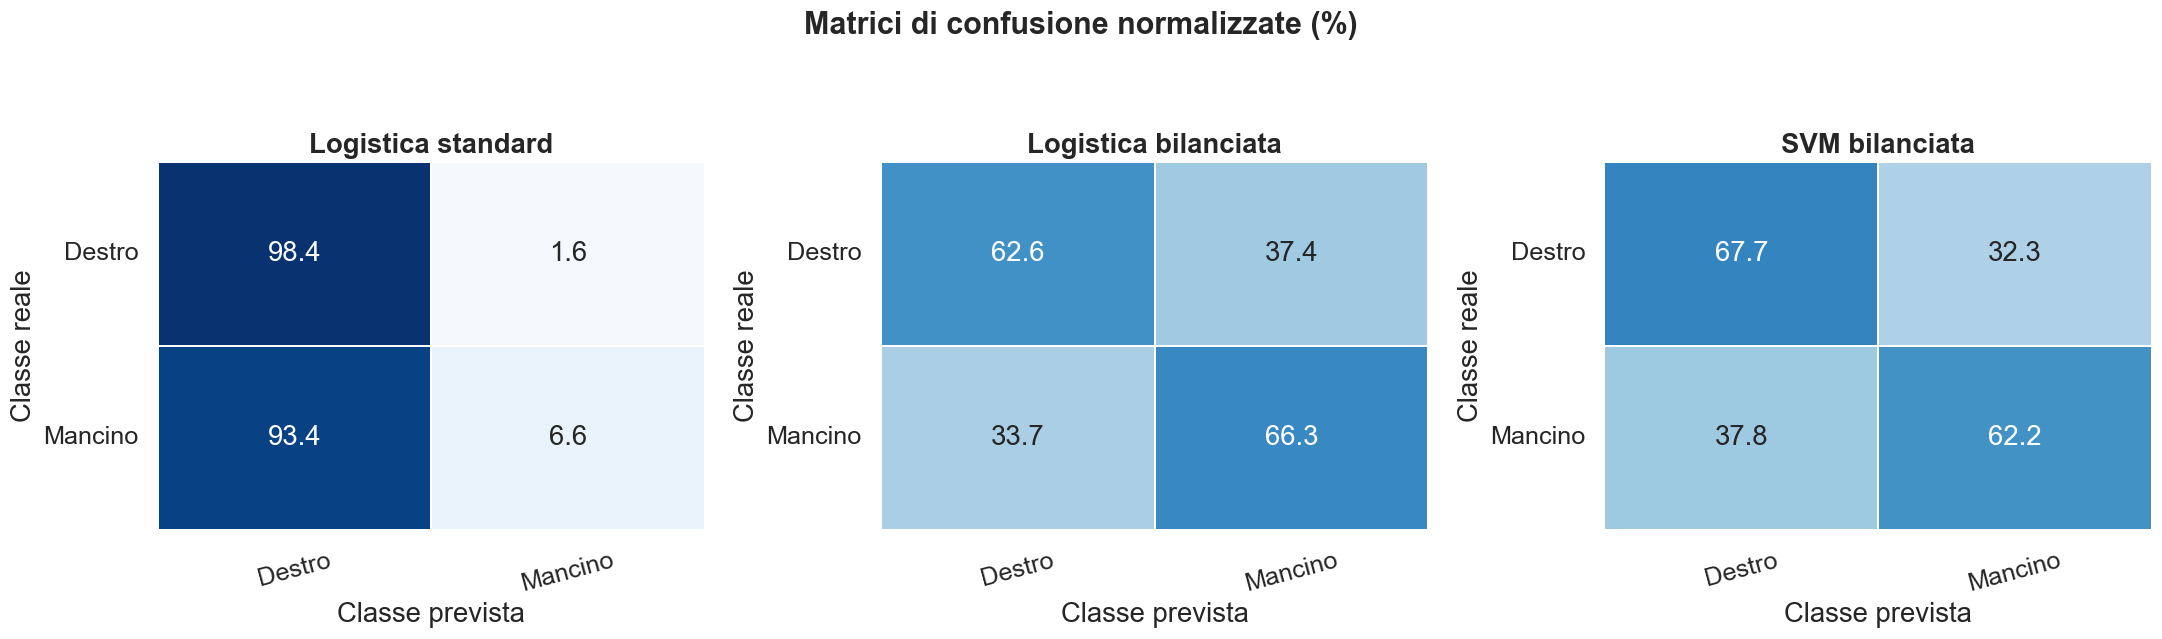

In [7]:
models_for_confusion = [
    'Logistica standard',
    'Logistica bilanciata',
    'SVM bilanciata',
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, model_name in zip(axes, models_for_confusion):
    matrix = confusion_matrix(
        y_test,
        predictions[model_name]['test'],
        labels=[0, 1],
        normalize='true',
    )
    sns.heatmap(
        matrix * 100,
        annot=True,
        fmt='.1f',
        cmap='Blues',
        vmin=0,
        vmax=100,
        linewidths=1,
        cbar=False,
        xticklabels=FOOT_LABELS,
        yticklabels=FOOT_LABELS,
        ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe reale')
    ax.tick_params(axis='x', rotation=15)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Matrici di confusione normalizzate (%)', fontsize=20, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / '09_matrici_confusione_piede.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Interpretazione della regressione logistica bilanciata

I coefficienti mostrano le associazioni utilizzate dal modello. Poiché le caratteristiche sono standardizzate, i coefficienti sono confrontabili: valori positivi favoriscono la previsione `Mancino`, mentre valori negativi favoriscono `Destro`.

Si tratta di associazioni statistiche interne al modello e non di relazioni causali.

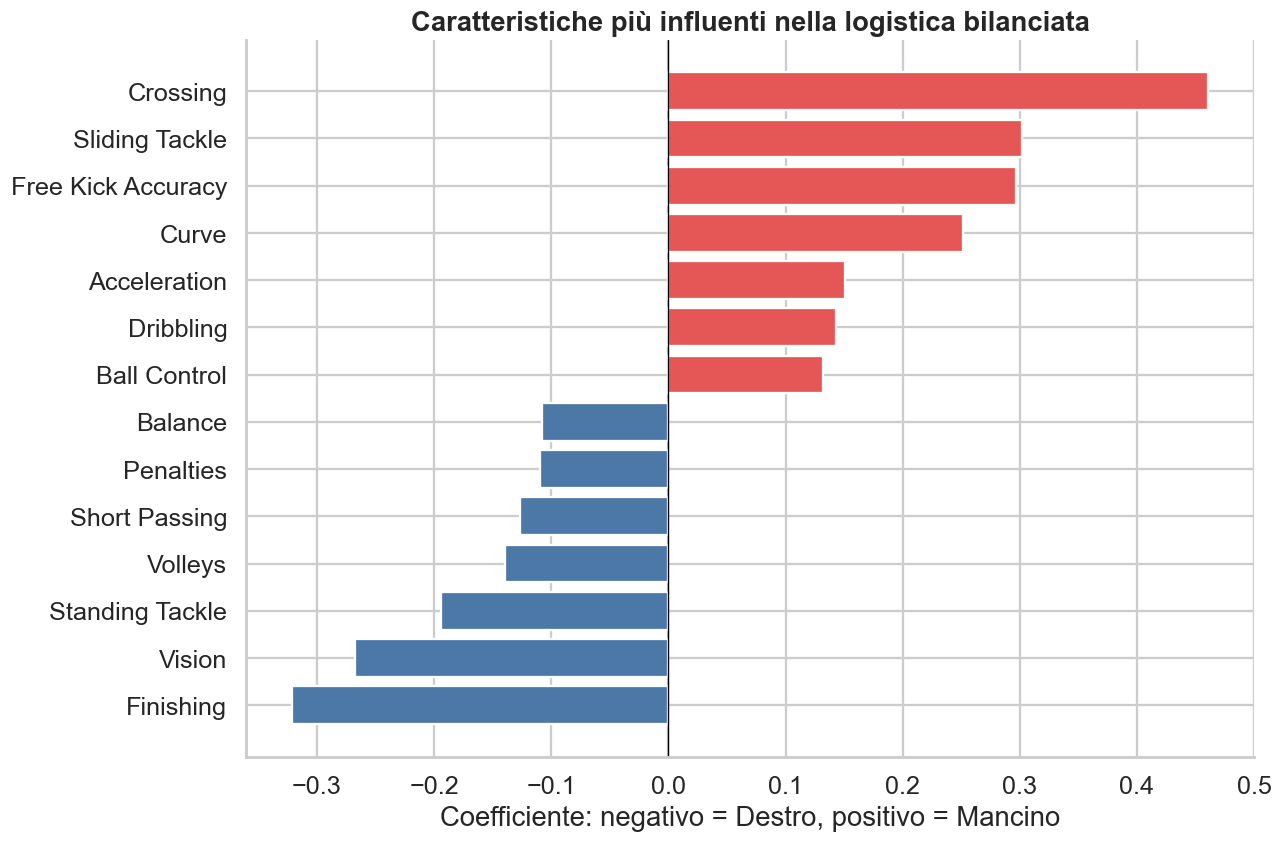

,Coefficiente
Crossing,0.4610
Sliding Tackle,0.3014
Free Kick Accuracy,0.2965
Curve,0.2516
Acceleration,0.1509
Dribbling,0.1428
Ball Control,0.1318
Balance,-0.1077
Penalties,-0.1095
Short Passing,-0.1269


In [8]:
balanced_coefficients = pd.Series(
    logistic_balanced.coef_[0],
    index=technical_features,
)
selected_features = balanced_coefficients.abs().nlargest(14).index
selected_coefficients = balanced_coefficients.loc[selected_features].sort_values()
coefficient_colors = [
    '#e45756' if value > 0 else '#4c78a8'
    for value in selected_coefficients
]

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(
    selected_coefficients.index,
    selected_coefficients.values,
    color=coefficient_colors,
)
ax.axvline(0, color='black', linewidth=0.9)
ax.set_title('Caratteristiche più influenti nella logistica bilanciata')
ax.set_xlabel('Coefficiente: negativo = Destro, positivo = Mancino')
ax.set_ylabel('')
fig.tight_layout()
fig.savefig(FIG_DIR / '10_coefficienti_piede.png', dpi=300, bbox_inches='tight')
plt.show()

display(
    selected_coefficients.sort_values(ascending=False)
    .rename('Coefficiente')
    .to_frame()
    .style.format('{:.4f}')
)

## 8. Conclusioni

- Il 75,1% dei giocatori è destro: questo valore costituisce il riferimento corretto per l'accuracy.
- La regressione logistica standard supera il riferimento di poco e riconosce una quota molto ridotta di mancini.
- Il bilanciamento aumenta sensibilmente la recall dei mancini, ma produce anche più falsi positivi e riduce l'accuracy complessiva.
- La SVM bilanciata presenta il miglior F1-score macro, mentre la regressione logistica bilanciata raggiunge la recall più elevata per i mancini.
- Nessun modello ottiene contemporaneamente precision e recall elevate sulla classe minoritaria.

Le statistiche tecniche contengono quindi un segnale associato al piede preferito, ma il segnale è debole. Questo risultato è utile perché mostra come un'accuracy apparentemente buona possa nascondere prestazioni molto scarse sulla classe meno numerosa.

In [9]:
print('RISULTATI PRINCIPALI')
print('-' * 70)
for model_name in metrics_table.index:
    print(
        f'{model_name}: '
        f'accuracy={metrics_table.loc[model_name, "Accuracy test"]:.4f}, '
        f'recall mancini={metrics_table.loc[model_name, "Recall mancini"]:.4f}, '
        f'F1 mancini={metrics_table.loc[model_name, "F1 mancini"]:.4f}, '
        f'F1 macro={metrics_table.loc[model_name, "F1 macro"]:.4f}'
    )

RISULTATI PRINCIPALI
----------------------------------------------------------------------
Riferimento: accuracy=0.7512, recall mancini=0.0000, F1 mancini=0.0000, F1 macro=0.4290
Logistica standard: accuracy=0.7558, recall mancini=0.0655, F1 mancini=0.1178, F1 macro=0.4881
Logistica bilanciata: accuracy=0.6355, recall mancini=0.6630, F1 mancini=0.4751, F1 macro=0.5980
SVM bilanciata: accuracy=0.6631, recall mancini=0.6221, F1 mancini=0.4789, F1 macro=0.6150
